## 0. Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from math import sqrt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, accuracy_score
import tensorflow as tf
from keras.models import Model
from keras.layers import (Input, Conv2D, MaxPooling2D, Permute, Reshape, Dense,
                                     Embedding, GRU, Bidirectional, AdditiveAttention, Concatenate,
                                     BatchNormalization, Dropout)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

I0000 00:00:1795426280.624965  145262 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795426280.651325  145262 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795426281.237504  145262 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Read dataset

In [2]:
images = np.load("../datasets/images.npy", mmap_mode="r")
labels = np.load("../datasets/labels.npy")

max_len = max(len(str(label)) for label in labels)

print("Number of images:", len(images))
print("Image shape:", images.shape)
print("Maximum label length:", max_len)

Number of images: 60000
Image shape: (60000, 28, 224, 1)
Maximum label length: 8


In [3]:
IMG_SHAPE = (28, 224, 1)
MAX_LABEL_LENGTH = 8  
MAX_OUTPUT_LENGTH = MAX_LABEL_LENGTH + 1

PAD_TOKEN = 10
START_TOKEN = 11
END_TOKEN = 12

VOCAB_SIZE = 13  # 0-9, PAD, START, END

VERSION = "cnn_bidirectional_attention_gru"  

## 2. Preprocessing

In [ ]:
seq = np.full((len(labels), MAX_OUTPUT_LENGTH + 1), PAD_TOKEN, dtype=np.int64)
for i, label in enumerate(labels):
    digits = [int(d) for d in str(label)]
    seq[i, 0] = START_TOKEN
    seq[i, 1 : len(digits) + 1] = digits
    seq[i, len(digits) + 1] = END_TOKEN

dec_in = seq[:, :-1]
dec_out = seq[:, 1:]

In [5]:
print("Maximum digit length:", MAX_LABEL_LENGTH)
print("Target length:", MAX_OUTPUT_LENGTH)

print("\nExample labels:")
for i in range(3):
    print("Original:", labels[i])
    print("Decoder input:", dec_in[i])
    print("Decoder target:", dec_out[i])
    print()

Maximum digit length: 8
Target length: 9

Example labels:
Original: 6290448
Decoder input: [11  6  2  9  0  4  4  8 12]
Decoder target: [ 6  2  9  0  4  4  8 12 10]

Original: 101651
Decoder input: [11  1  0  1  6  5  1 12 10]
Decoder target: [ 1  0  1  6  5  1 12 10 10]

Original: 36731246
Decoder input: [11  3  6  7  3  1  2  4  6]
Decoder target: [ 3  6  7  3  1  2  4  6 12]



## 3. Data Split

Chia train/val/test = 70/15/15

In [ ]:
idx = np.arange(len(images))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=42)

X_train, X_val, X_test = images[idx_train], images[idx_val], images[idx_test]
Din_train, Din_val = dec_in[idx_train], dec_in[idx_val]
Dout_train, Dout_val = dec_out[idx_train], dec_out[idx_val]
y_train, y_test = labels[idx_train], labels[idx_test]

print('Train:', X_train.shape)
print('Validation:', X_val.shape)
print('Test:', X_test.shape)

Train: (42000, 28, 224, 1)
Validation: (9000, 28, 224, 1)
Test: (9000, 28, 224, 1)


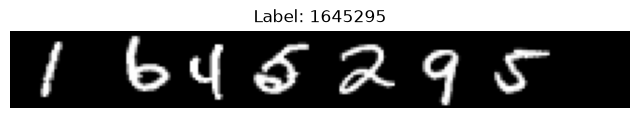

In [7]:
plt.figure(figsize=(8, 2))
plt.imshow(X_train[2].squeeze(), cmap='gray')
plt.title(f"Label: {y_train[2]}")
plt.axis('off')
plt.show()

## 4. Train model

In [ ]:
units = 128

# Encoder (CNN + Bidirectional GRU)
img_input = Input(shape=IMG_SHAPE)                    # (28, 224, 1)
x = Conv2D(32, (3, 3), padding='same', activation='relu')(img_input)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2))(x)                         # (14, 112, 32)
x = Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2))(x)                         # (7, 56, 64)
x = Conv2D(128, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((7, 1))(x)                         # (1, 56, 128)

# Chuyển feature map thành chuỗi từ trái sang phải, giữ 56 vị trí ngang.
h, w, c = x.shape[1], x.shape[2], x.shape[3]
x = Permute((2, 1, 3))(x)
x = Reshape((w, h * c))(x)                          # (56, 128)


enc_out, forward_h, backward_h = Bidirectional(
    GRU(units // 2, return_sequences=True, return_state=True),
    merge_mode='concat'
)(x)
state_h = Concatenate()([forward_h, backward_h])    # (batch, 128)

# Decoder (GRU + Additive Attention)
dec_input = Input(shape=(MAX_OUTPUT_LENGTH,))
emb = Embedding(VOCAB_SIZE, 64)(dec_input)
dec_out = GRU(units, return_sequences=True)(emb, initial_state=[state_h])

context = AdditiveAttention()([dec_out, enc_out])
merged = Concatenate()([dec_out, context])
z = Dense(256, activation='relu')(merged)
outputs = Dense(VOCAB_SIZE, activation='softmax')(z)


I0000 00:00:1795426282.532457  145262 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 11976 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Ti SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


In [9]:
model = Model(inputs=[img_input, dec_input], outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', weighted_metrics=['sparse_categorical_accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 28, 224,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 224,   │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 28, 224,   │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 14, 112,   │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 14, 112,   │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 112,   │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 7, 56, 64) │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 7, 56,     │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 56,     │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 1, 56,     │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 56, 1,     │          0 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 56, 128)   │          0 │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ [(None, 56, 128), │     74,496 │ reshape[0][0]     │
│ (Bidirectional)     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 9, 64)     │        832 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ bidirectional[0]… │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 9, 128)    │     74,496 │ embedding[0][0],

 Total params: 312,653 (1.19 MB)

 Trainable params: 312,205 (1.19 MB)

 Non-trainable params: 448 (1.75 KB)

In [10]:
train_mask = (Dout_train != PAD_TOKEN).astype('float64')
val_mask = (Dout_val != PAD_TOKEN).astype('float64')

early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

history = model.fit([X_train, Din_train], Dout_train, 
                    sample_weight=train_mask, 
                    epochs=50, 
                    batch_size=64, 
                    verbose=1, 
                    validation_data=([X_val, Din_val], Dout_val, val_mask), 
                    callbacks=[early_stop, reduce_lr])

Epoch 1/50


I0000 00:00:1795426285.190213  145429 cuda_dnn.cc:461] Loaded cuDNN version 92801


657/657 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - loss: 0.5592 - sparse_categorical_accuracy: 0.7486 - val_loss: 0.0982 - val_sparse_categorical_accuracy: 0.9624 - learning_rate: 0.0010
Epoch 2/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - loss: 0.0390 - sparse_categorical_accuracy: 0.9863 - val_loss: 0.0292 - val_sparse_categorical_accuracy: 0.9896 - learning_rate: 0.0010
Epoch 3/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - loss: 0.0177 - sparse_categorical_accuracy: 0.9936 - val_loss: 0.0240 - val_sparse_categorical_accuracy: 0.9906 - learning_rate: 0.0010
Epoch 4/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - loss: 0.0162 - sparse_categorical_accuracy: 0.9940 - val_loss: 0.0192 - val_sparse_categorical_accuracy: 0.9931 - learning_rate: 0.0010
Epoch 5/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - loss: 0.0087 - sparse_categorical_accuracy: 0.9968 - val_loss: 0.0163 - val_sparse_categorical_accuracy: 0.9941 - learning_rate: 0.0010
Epoch 6/50
657/657 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/st

## 5. Prediction

In [ ]:
n_samples = len(X_test)
test_dec_in = np.full((n_samples, MAX_OUTPUT_LENGTH), PAD_TOKEN, dtype=np.int64)
test_dec_in[:, 0] = START_TOKEN

for t in range(MAX_OUTPUT_LENGTH):
    preds = model.predict([X_test, test_dec_in], batch_size=256, verbose=0)

    # Chỉ cho phép dự đoán digit hoặc END
    logits = preds[:, t, :].copy()
    logits[:, PAD_TOKEN] = -1
    logits[:, START_TOKEN] = -1
    next_token = np.argmax(logits, axis=-1)

    if t + 1 < MAX_OUTPUT_LENGTH:
        test_dec_in[:, t + 1] = next_token

outputs = []
for seq in test_dec_in[:, 1:]:
    output = []
    for token in seq:
        if token >= 10:
            break
        output.append(str(token))
    outputs.append(float(''.join(output)) if output else 0.0)

y_pred = np.array(outputs, dtype=np.float64)

## 6. Evaluation

In [12]:
y_true_num = np.array(y_test, dtype=np.float64)
y_pred_num = np.array(y_pred, dtype=np.float64)

mae     = mean_absolute_error(y_true_num, y_pred_num)
rmse    = np.sqrt(mean_squared_error(y_true_num, y_pred_num))
r2      = r2_score(y_true_num, y_pred_num)
nse_denom   = np.sum((y_true_num - np.mean(y_true_num)) ** 2)
nse     = 1.0 - np.sum((y_true_num - y_pred_num) ** 2) / nse_denom if nse_denom else np.nan
acc     = accuracy_score(y_true_num, y_pred_num)

print(f"Sequence Accuracy: {acc:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2:   {r2:.4f}")
print(f"NSE:  {nse:.4f}")

Sequence Accuracy: 0.9933
MAE:  11431.7633
RMSE: 658580.5963
R2:   0.9988
NSE:  0.9988


### Save Result

In [ ]:
output_path = "../output/KietModel/"  
csv_path = output_path + "kiet_model_results.csv"   
model_path = output_path + f"kiet_model_{VERSION}.keras"   

import os
os.makedirs(output_path, exist_ok=True)

model.save(model_path)  

results = {
    "Model": f"Kiet Model {VERSION}",     
    "Version": VERSION,
    "Sequence_Accuracy": acc,
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2,
    "NSE": nse
}

results_df = pd.DataFrame([results])

if os.path.exists(csv_path):
    results_df = pd.concat([pd.read_csv(csv_path), results_df], ignore_index=True)
results_df.to_csv(csv_path, index=False)

print(f"Model saved: {model_path}")
print(f"Results saved: {csv_path}")

Model saved: ../output/KietModel/kiet_model_cnn_bidirectional_attention_gru.keras
Results saved: ../output/KietModel/kiet_model_results.csv


: 